In [1]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import glob
from collections import defaultdict
from tqdm import tqdm

path = "data" 
OUT = "prepared"      
SEED = 42             
print(os.listdir(path))
np.random.seed(1)

['csv', 'jpeg']


In [2]:
train = pd.read_csv(os.path.join(path, "csv", "mass_case_description_train_set.csv"))
test = pd.read_csv(os.path.join(path, "csv", "mass_case_description_test_set.csv"))
print(train.shape, test.shape)
train.head()

(1318, 14) (378, 14)


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


In [3]:
df = pd.concat([train, test], ignore_index=True)
print(df.shape)
df["pathology"].value_counts()

(1696, 14)


pathology
MALIGNANT                  784
BENIGN                     771
BENIGN_WITHOUT_CALLBACK    141
Name: count, dtype: int64

In [4]:
df["pathology"] = df["pathology"].replace("BENIGN_WITHOUT_CALLBACK", "BENIGN")
df["label"] = (df["pathology"] == "MALIGNANT").astype(int)
df["label"].value_counts()

label
0    912
1    784
Name: count, dtype: int64

In [5]:
patients = df["patient_id"].unique() # removing any duplicated

In [6]:
from sklearn.model_selection import train_test_split

train_id, rest_id = train_test_split(patients, test_size=0.30, random_state=28) # 70% / 30%
val_id, test_id   = train_test_split(rest_id, test_size=1/3, random_state=28) # 20% / 10%

train_df = df[df["patient_id"].isin(train_id)]
val_df = df[df["patient_id"].isin(val_id)]
test_df = df[df["patient_id"].isin(test_id)]

print(f"Crops: Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")
print(f"Patients: Train size: {len(train_id)}, Val size: {len(val_id)}, Test size: {len(test_id)}")

# keep a "split" column on df, because Step 8 uses it when saving the images
df["split"] = "train"
df.loc[df["patient_id"].isin(val_id), "split"] = "val"
df.loc[df["patient_id"].isin(test_id), "split"] = "test"

Crops: Train size: 1177, Val size: 350, Test size: 169
Patients: Train size: 624, Val size: 178, Test size: 90


In [7]:
max_splits = df.groupby("patient_id")["split"].nunique().max()
print("Max splits per patient:", max_splits, "(must be 1)")
assert max_splits == 1

table = pd.crosstab(df["split"], df["label"], margins=True)
table.columns = ["benign", "malignant", "total"]
table = table.reindex(["train", "val", "test", "All"])
table["patients"] = [len(train_id), len(val_id), len(test_id), len(patients)]
table["% malignant"] = (100 * table["malignant"] / table["total"]).round(1)
table

Max splits per patient: 1 (must be 1)


,benign,malignant,total,patients,% malignant
split,,,,,
train,639,538,1177,624,45.7
val,184,166,350,178,47.4
test,89,80,169,90,47.3
All,912,784,1696,892,46.2


In [8]:
df.to_csv("splits.csv", index=False)
print("Saved splits.csv")

Saved splits.csv


In [9]:
images_path = defaultdict(list)
for x in glob.glob(os.path.join(path, "jpeg", "*", "*.jpg")):
    images_path[os.path.basename(os.path.dirname(x))].append(x)
print("folders:", len(images_path))

folders: 6774


In [ ]:
def series_uid(dicom_path):
    return str(dicom_path).strip().replace("\\", "/").split("/")[-2]

def is_mask(img):
    return np.logical_and(img > 20, img < 235).mean() < 0.01   # almost only black and white

def find_paths(row):
    full = images_path.get(series_uid(row["image file path"]), [None])[0]
    files = set(images_path.get(series_uid(row["cropped image file path"]), []) +
                images_path.get(series_uid(row["ROI mask file path"]), []))
    crop = mask = None
    for f in files:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        if img is None: # unreadable file
            continue
        if is_mask(img):
            mask = f
        else:
            crop = f
    return pd.Series({"full_path": full, "crop_path": crop, "mask_path": mask})

tqdm.pandas()
df[["full_path", "crop_path", "mask_path"]] = df.progress_apply(find_paths, axis=1)
print("missing paths:\n", df[["full_path", "crop_path", "mask_path"]].isna().sum())
df = df.dropna(subset=["full_path", "crop_path", "mask_path"]).reset_index(drop=True)
print("masses kept:", len(df))
df[["patient_id", "label", "split", "crop_path"]].head()

100%|██████████| 1696/1696 [02:25<00:00, 11.64it/s]


missing paths:
 full_path    0
crop_path    0
mask_path    0
dtype: int64
masses kept: 1696


,patient_id,label,split,crop_path
0,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.29673640331...
1,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.22795527471...
2,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.42912041401...
3,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.11513423211...
4,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.12857366312...


In [21]:
df[["patient_id", "label", "split", "full_path"]].head()

,patient_id,label,split,full_path
0,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.34238619481...
1,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.35930832931...
2,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.89180046211...
3,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.29536092631...
4,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.41052475491...


In [22]:
df[["patient_id", "label", "split", "mask_path"]].head()

,patient_id,label,split,mask_path
0,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.29673640331...
1,P_00001,1,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.22795527471...
2,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.42912041401...
3,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.11513423211...
4,P_00004,0,train,data\jpeg\1.3.6.1.4.1.9590.100.1.2.12857366312...


In [ ]:
SIZE = 224
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def pad_to_square(img):
    h, w = img.shape
    s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    return cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left, cv2.BORDER_CONSTANT, value=0)

def get_img(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)                  # grayscale
    img = pad_to_square(img)                                          # keep the mass's shape
    img = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    img = clahe.apply(img)                                            # CLAHE
    return img

x_crop = np.array([get_img(p) for p in tqdm(df["crop_path"].values)], dtype=np.float32) / 255.0
x_crop = x_crop[:, np.newaxis, :, :] # reshape to (N, 1, 224, 224) for PyTorch
y = df["label"].values
print(x_crop.shape, x_crop.min(), x_crop.max())

100%|██████████| 1696/1696 [00:23<00:00, 72.79it/s]


(1696, 1, 224, 224) 0.003921569 1.0


In [ ]:
def get_context(full_path, mask_path, scale=2.0):
    full = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask.shape != full.shape:
        mask = cv2.resize(mask, (full.shape[1], full.shape[0]), interpolation=cv2.INTER_NEAREST)
    ys, xs = np.nonzero(mask > 127)  # where the mass is
    if len(xs) == 0:
        return None  # empty mask
    cx, cy = (xs.min() + xs.max()) // 2, (ys.min() + ys.max()) // 2  # its centre
    side = int(max(xs.max() - xs.min(), ys.max() - ys.min()) * scale) + 1   # 2x the mass size
    big = cv2.copyMakeBorder(full, side, side, side, side, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    ctx = big[y0 : y0 + side, x0 : x0 + side]
    ctx = cv2.resize(ctx, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return clahe.apply(ctx)

ctx_list = [get_context(f, m) for f, m in tqdm(zip(df["full_path"], df["mask_path"]), total=len(df))]
good = np.array([c is not None for c in ctx_list])
if not good.all():                                                    # drop masses with an empty mask everywhere
    print("dropping", (~good).sum(), "masses with an empty mask")
    df, x_crop, y = df[good].reset_index(drop=True), x_crop[good], y[good]
x_ctx = np.array([c for c in ctx_list if c is not None], dtype=np.float32) / 255.0
x_ctx = x_ctx[:, np.newaxis, :, :]
print(x_ctx.shape)

100%|██████████| 1696/1696 [03:46<00:00,  7.47it/s]


(1696, 1, 224, 224)


In [ ]:
is_train = (df["split"] == "train").values
is_val = (df["split"] == "val").values
is_test = (df["split"] == "test").values

x_train, y_train = x_crop[is_train], y[is_train]
x_val, y_val = x_crop[is_val],   y[is_val]
x_test, y_test = x_crop[is_test],  y[is_test]

MEAN, STD = x_train.mean(), x_train.std() # from TRAINING images only
x_train = (x_train - MEAN) / STD
x_val = (x_val - MEAN) / STD
x_test = (x_test - MEAN) / STD
print("train", x_train.shape, "val", x_val.shape, "test", x_test.shape, "| mean", MEAN, "std", STD)

train (1177, 1, 224, 224) val (350, 1, 224, 224) test (169, 1, 224, 224) | mean 0.47764143 std 0.24925417


In [14]:
np.save("x_crop.npy", x_crop); np.save("x_ctx.npy", x_ctx)
df.to_csv("df_with_paths.csv", index=False)

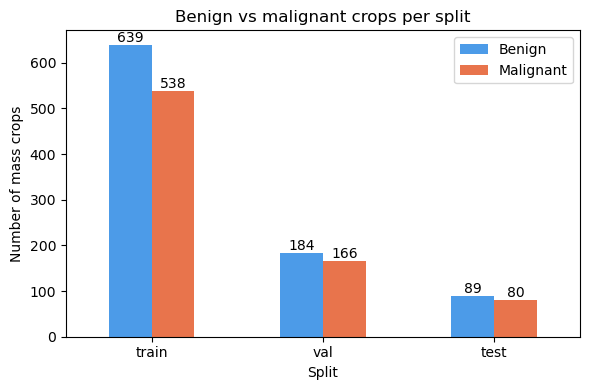

In [15]:
counts = pd.crosstab(df["split"], df["label"]).reindex(["train", "val", "test"])
counts.columns = ["Benign", "Malignant"]
ax = counts.plot(kind="bar", figsize=(6, 4), color=["#4C9BE8", "#E8744C"], rot=0)
for c in ax.containers:
    ax.bar_label(c)                       # numbers on top of each bar
ax.set_xlabel("Split"); ax.set_ylabel("Number of mass crops")
ax.set_title("Benign vs malignant crops per split")
plt.tight_layout(); plt.savefig("class_balance.png", dpi=150); plt.show()

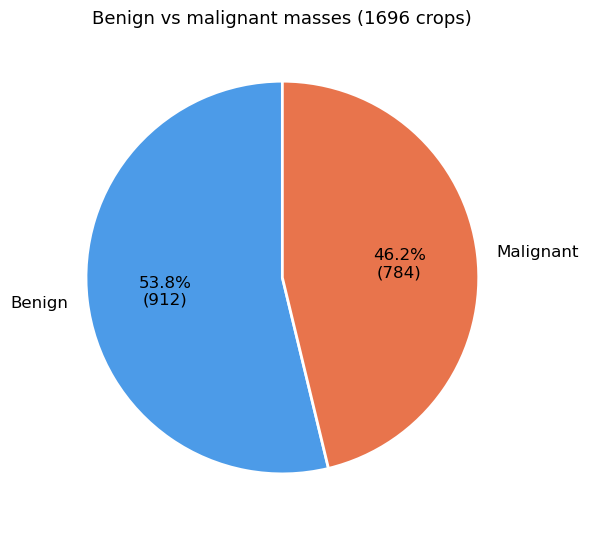

In [16]:
import matplotlib.pyplot as plt

counts = df["label"].value_counts().reindex([0, 1])     # 0 = benign, 1 = malignant
labels = ["Benign", "Malignant"]
colors = ["#4C9BE8", "#E8744C"]                          # same colours as the bar chart

plt.figure(figsize=(6, 6))
plt.pie(counts,
        labels=labels,
        colors=colors,
        startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        autopct=lambda pct: "{:.1f}%\n({:d})".format(pct, int(round(pct * counts.sum() / 100))),
        textprops={"fontsize": 12})
plt.title("Benign vs malignant masses ({} crops)".format(counts.sum()), fontsize=13)
plt.tight_layout()
plt.savefig("class_pie.png", dpi=150)
plt.show()

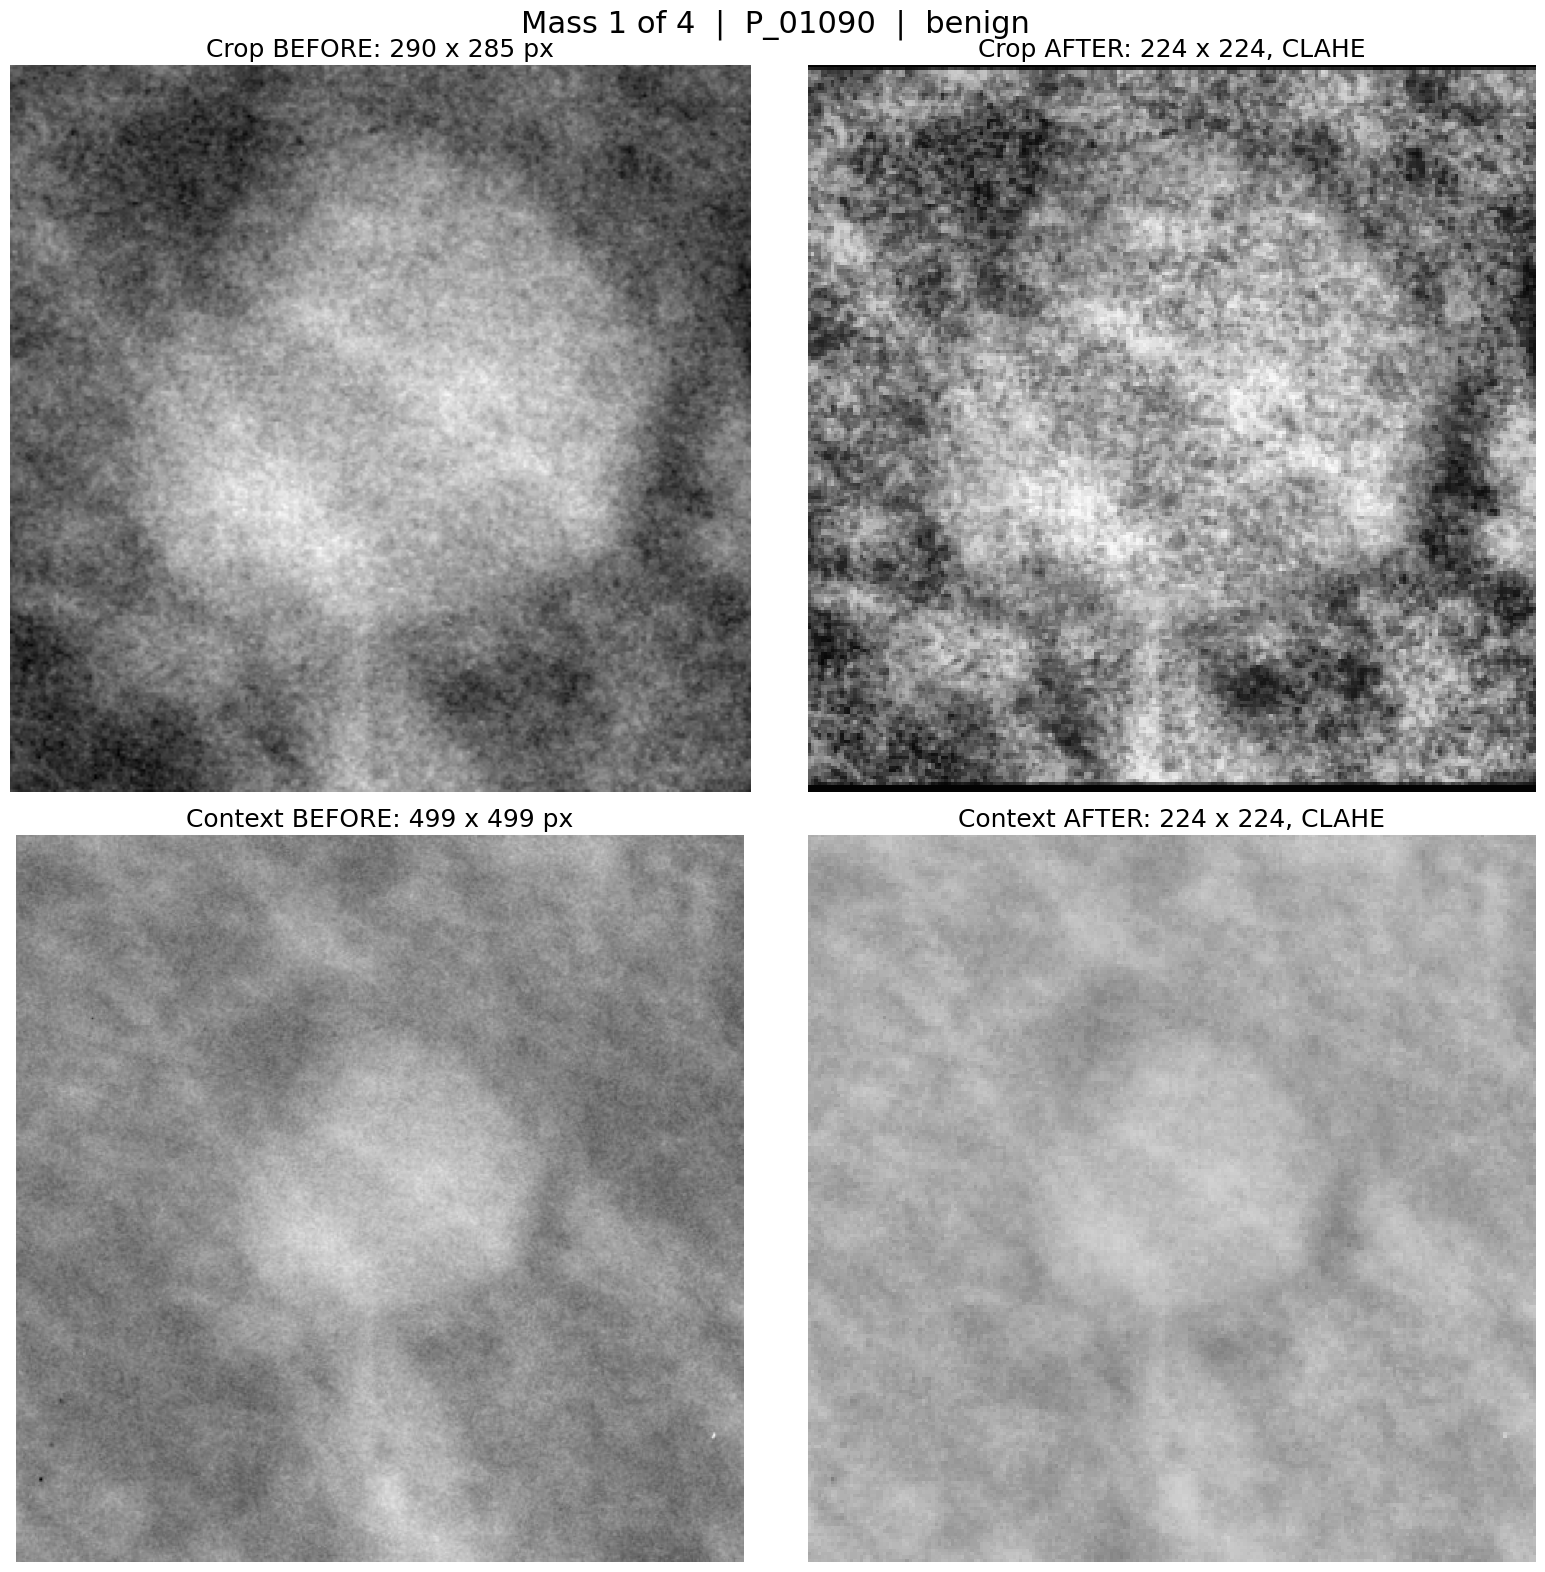

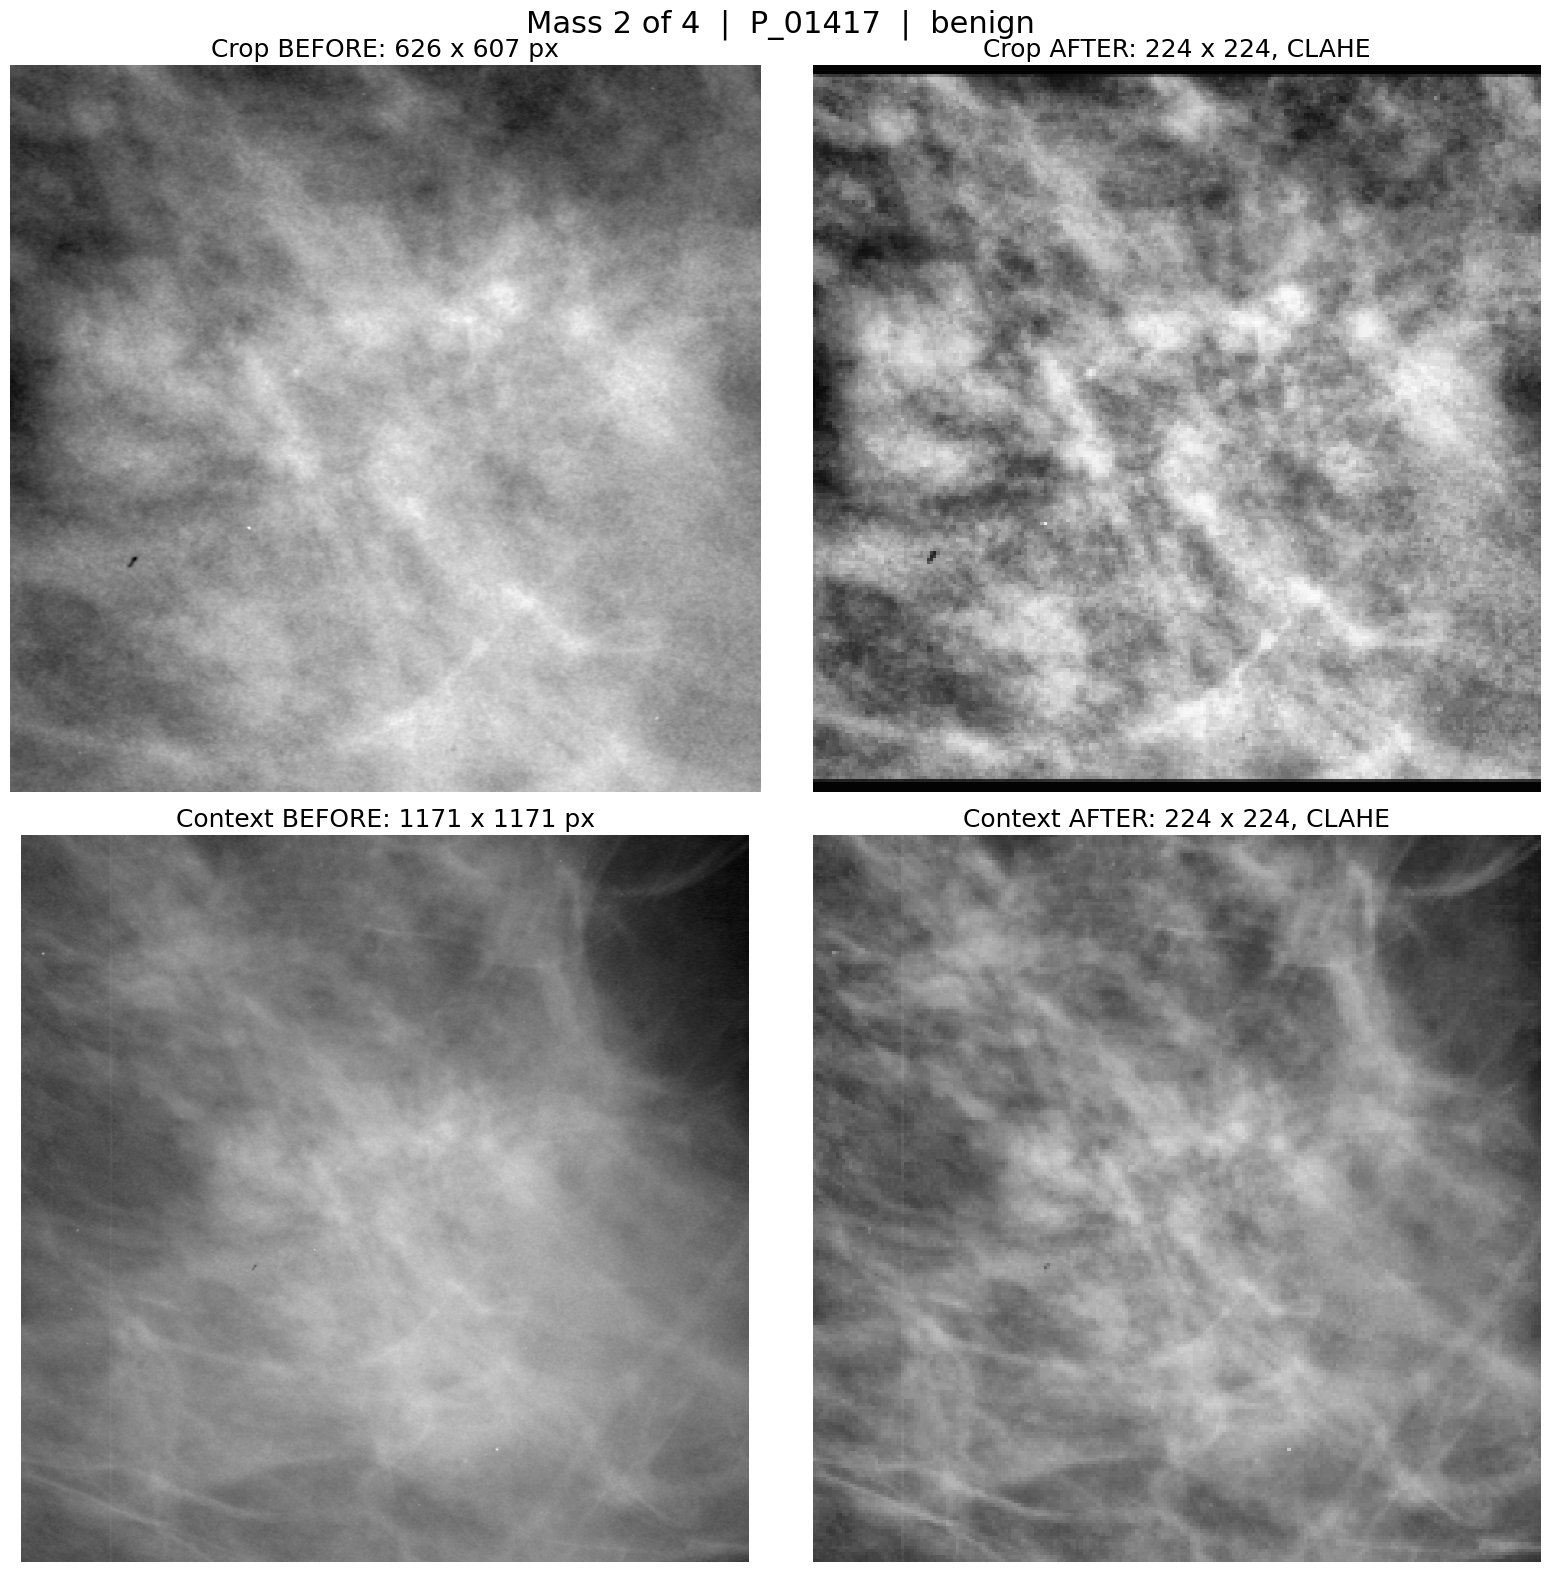

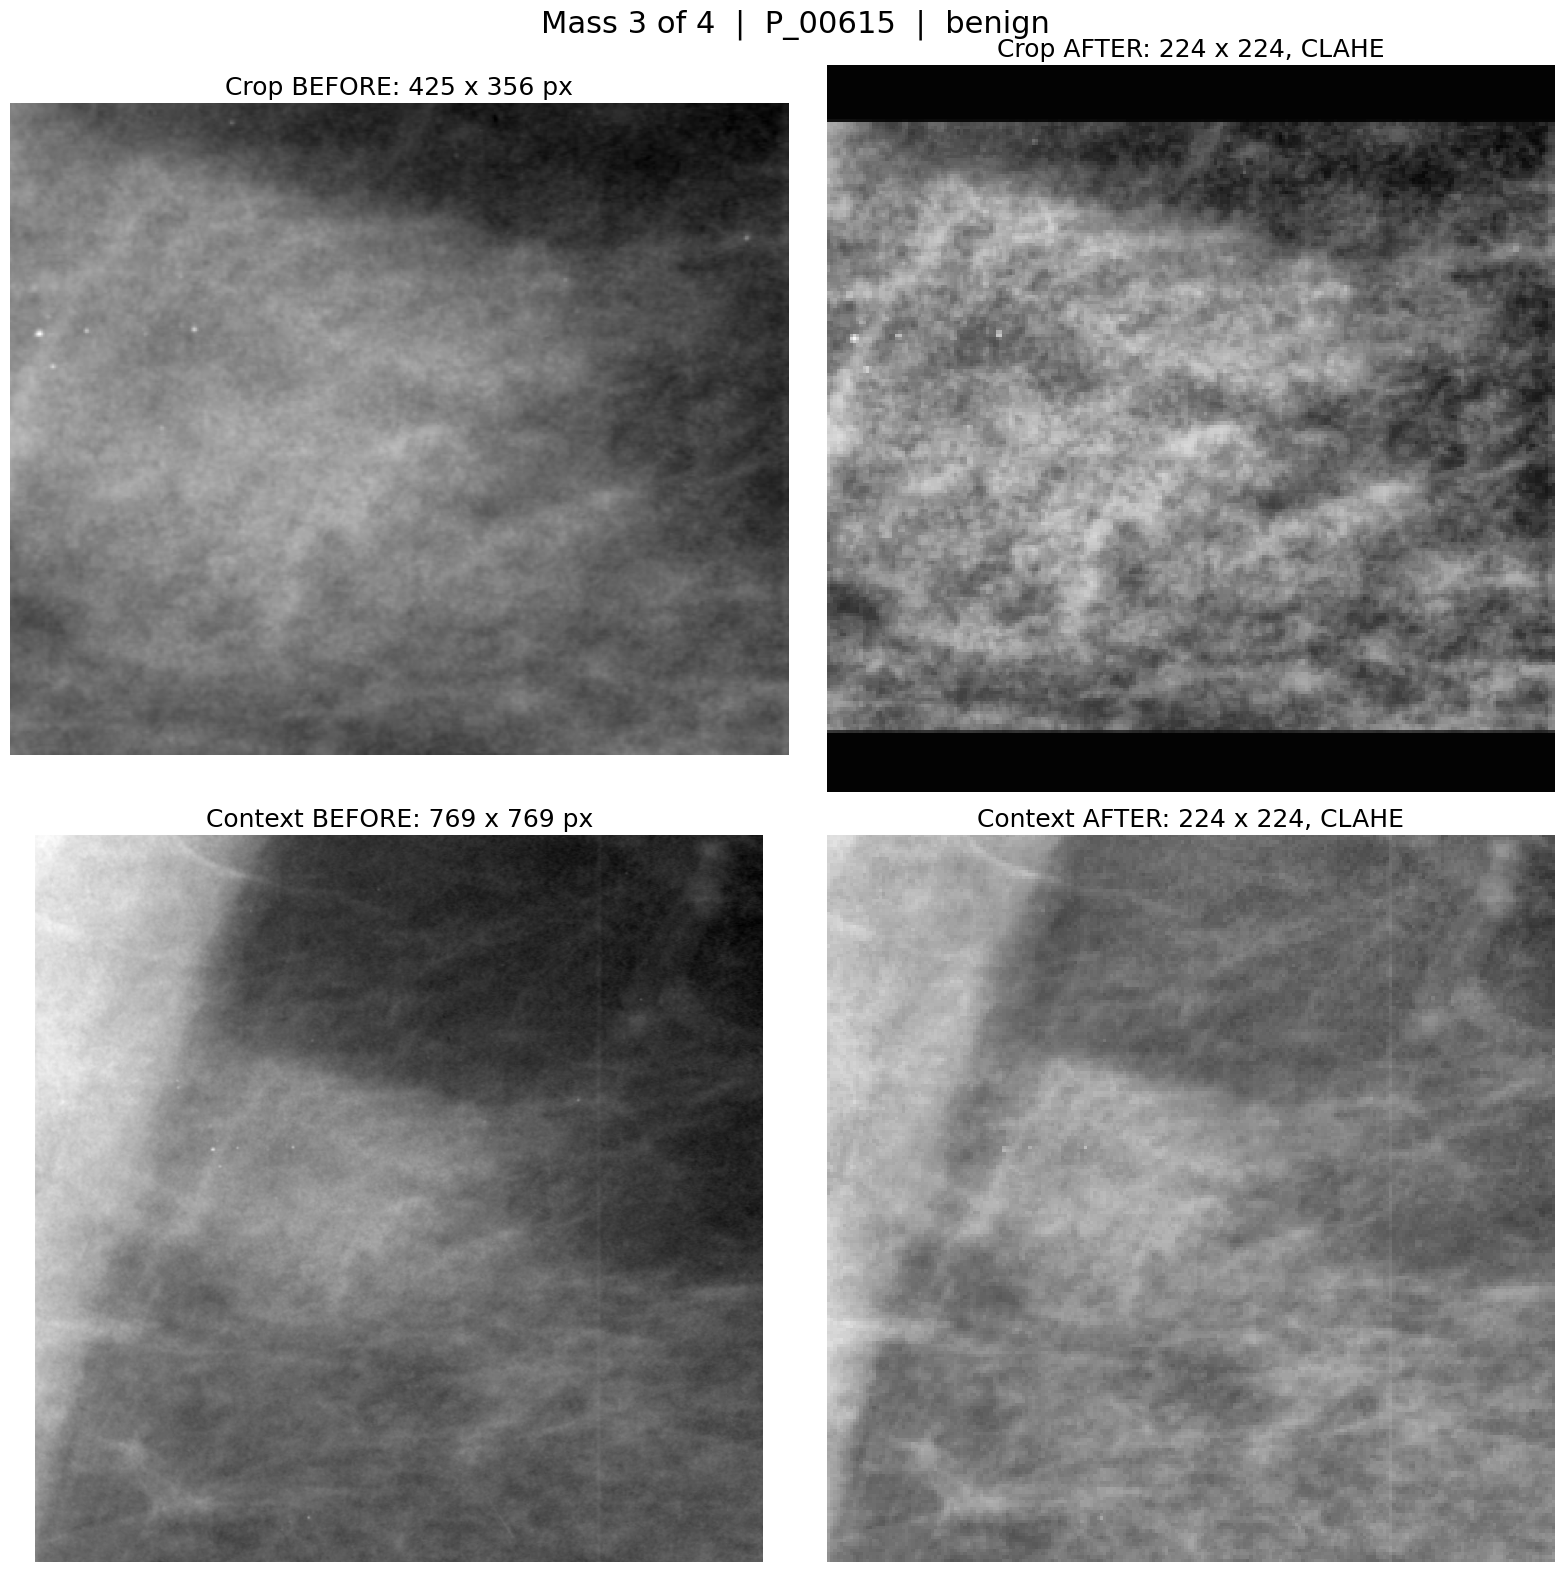

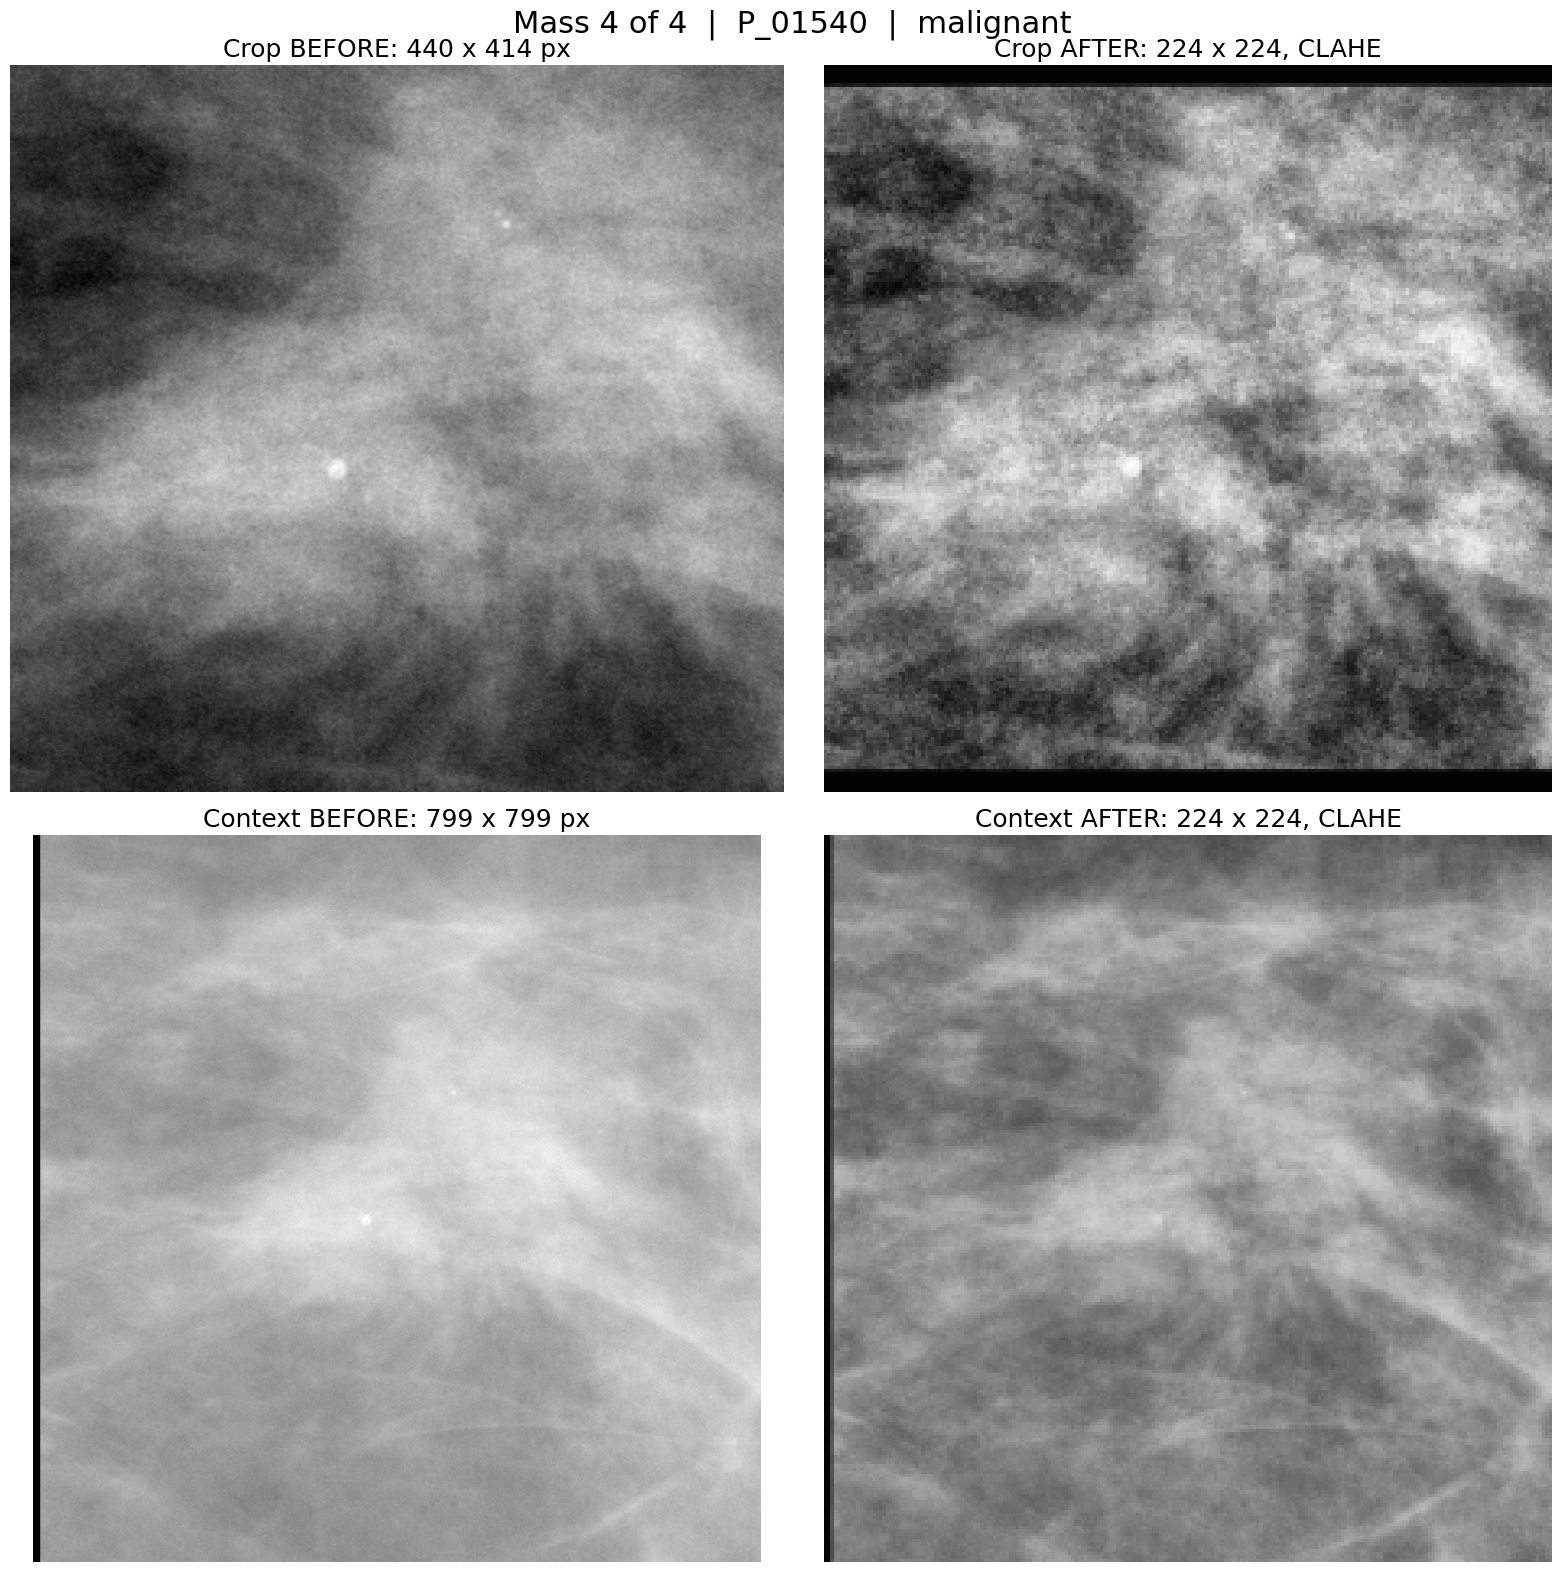

In [23]:
def raw_context(full_path, mask_path, scale=2.0):
    """The same 2x window as get_context, but before resizing and CLAHE."""
    full = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask.shape != full.shape:
        mask = cv2.resize(mask, (full.shape[1], full.shape[0]), interpolation=cv2.INTER_NEAREST)
    ys, xs = np.nonzero(mask > 127)
    cx, cy = (xs.min() + xs.max()) // 2, (ys.min() + ys.max()) // 2
    side = int(max(xs.max() - xs.min(), ys.max() - ys.min()) * scale) + 1
    big = cv2.copyMakeBorder(full, side, side, side, side, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    return big[y0 : y0 + side, x0 : x0 + side]

n = 4                                         # how many masses to show
rows = df.sample(n, random_state=1).index     # pick 4 random masses

for k, i in enumerate(rows):
    raw_crop = cv2.imread(df.loc[i, "crop_path"], cv2.IMREAD_GRAYSCALE)        # original crop, no changes
    raw_ctx = raw_context(df.loc[i, "full_path"], df.loc[i, "mask_path"])     # original 2x window, no changes
    label = "malignant" if df.loc[i, "label"] == 1 else "benign"

    fig, axes = plt.subplots(2, 2, figsize=(16, 16))                          # big figure for each mass
    # top row: crop (stream 1)
    axes[0, 0].imshow(raw_crop, cmap="gray")
    axes[0, 0].set_title("Crop BEFORE: {} x {} px".format(raw_crop.shape[1], raw_crop.shape[0]), fontsize=18)
    axes[0, 1].imshow(x_crop[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Crop AFTER: 224 x 224, CLAHE", fontsize=18)
    # bottom row: context window (stream 2)
    axes[1, 0].imshow(raw_ctx, cmap="gray")
    axes[1, 0].set_title("Context BEFORE: {} x {} px".format(raw_ctx.shape[1], raw_ctx.shape[0]), fontsize=18)
    axes[1, 1].imshow(x_ctx[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, 1].set_title("Context AFTER: 224 x 224, CLAHE", fontsize=18)
    for a in axes.flat:
        a.axis("off")

    fig.suptitle("Mass {} of {}  |  {}  |  {}".format(k + 1, n, df.loc[i, "patient_id"], label), fontsize=22)
    plt.tight_layout(); plt.savefig("before_after_{}.png".format(k + 1), dpi=150); plt.show()